# Теплица на аварийном питании

Настрой обогрев и свет, восстанови расход энергии и спрогнозируй рост растений.

Рядом с ноутбуком: `greenhouse_tools.py`, `greenhouse_data.npz`. Запусти первую кодовую ячейку; загрузка данных и графики уже настроены.

**Ответы в форме:** каждый пункт (`1а`, `1б`, …) — отдельное поле. Числа записывай с точкой и 6 знаками после неё, без единиц и подписей. Округляй только при выводе. Полный код GD — поле `1г`. (Форма: https://forms.gle/NRjDtjp9oy5qvkV19)

В задаче 1 напиши `gradient_descent` самостоятельно. Во всех следующих заданиях можно использовать эту функцию без повторного написания.

`answer(номер_задачи, [значения])` печатает ответы по пунктам с 6 знаками после точки. Например, `answer(1, [T_1, T_25, f_T25])` выведет `1а`, `1б`, `1в`: передавай значения в порядке пунктов и переноси в форму только числа.

In [2]:
from greenhouse_tools import *
import numpy as np

## 1. Градиентный спуск

Напиши `gradient_descent(grad_f, x0, learning_rate, n_steps)`.

$$
\theta_{k+1}=\theta_k-\alpha\nabla f(\theta_k).
$$

Верни NumPy-массивы `(x_final, history)`: конечную точку и все точки, включая начальную. Форма истории — `(n_steps + 1, len(x0))`. Сделай ровно `n_steps` обновлений; исходный `x0` не меняй.

$$
f(T)=(T-24)^2,\qquad f'(T)=2(T-24),\qquad
T_0=8,\quad\alpha=0.1,\quad N=25.
$$

Примени свой GD к этой функции.

**Ответы в форме** — по одному числу с точкой и 6 знаками после неё:

- **1а.** $T_1$
- **1б.** $T_{25}$
- **1в.** $f(T_{25})$
- **1г.** Полный код `gradient_descent` с отступами, без вызовов и вывода (поле «Абзац»).

In [3]:
def temperature_loss(x):
    return (x[0] - 24.0) ** 2

def temperature_gradient(x):
    return 2*(x[0]-24.0)


def gradient_descent(grad_f, x0, learning_rate, n_steps):
    x = np.array(x0, dtype=float)
    history = [x.copy()]
    for i in range(n_steps):
      x = x - learning_rate*grad_f(x)
      history.append(x.copy())

    return x, np.array(history)

# Запуск GD с параметрами из условия
x_1, history_1 = gradient_descent(temperature_gradient, np.array([8.0]), 0.1, 25)

1а: 11.200000
1б: 23.939554
1в: 0.003654


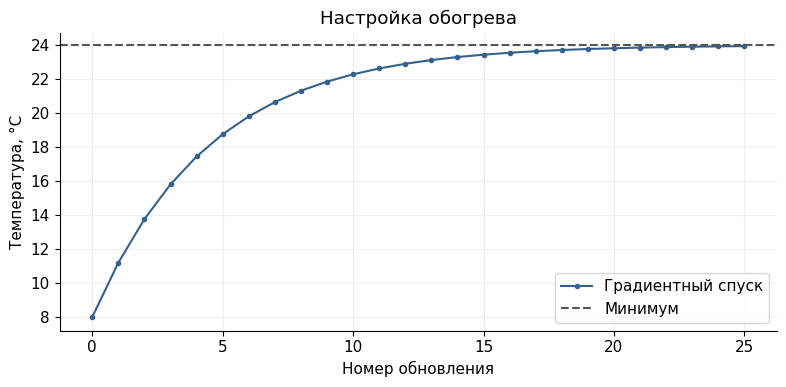

In [4]:
if history_1 is not None:
    answer(1, [history_1[1, 0], x_1[0], temperature_loss(x_1)])
    plot_temperature(history_1)

## 2. Проверка через SciPy

Сначала самостоятельно найди в документации SciPy описание `minimize` и пример вызова.

Найди минимум той же функции с тем же стартом: `method="BFGS"`, `jac=temperature_gradient`, `options={"gtol": 1e-8}`. Координаты результата — `result.x`.

Сравни с результатом своего GD из задачи 1:

$$
\Delta=\left|T_{25}^{\mathrm{GD}}-T^{\mathrm{SciPy}}\right|.
$$

Проверь, что $\Delta<0.1$.

**Ответы в форме** — по одному числу с точкой и 6 знаками после неё:

- **2а.** $T^{\mathrm{SciPy}}$
- **2б.** $f(T^{\mathrm{SciPy}})$
- **2в.** $\Delta$

<details>
<summary>Если не удалось найти — открыть ссылку</summary>

[Описание minimize и примеры](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.minimize.html)

</details>

In [5]:
import scipy

scipy_result = scipy.optimize.minimize(
    temperature_loss,
    np.array([8.0]),
    method="BFGS",
    jac=temperature_gradient,
    options={"gtol": 1e-8}
)

2а: 24.000000
2б: 0.000000
2в: 0.060446


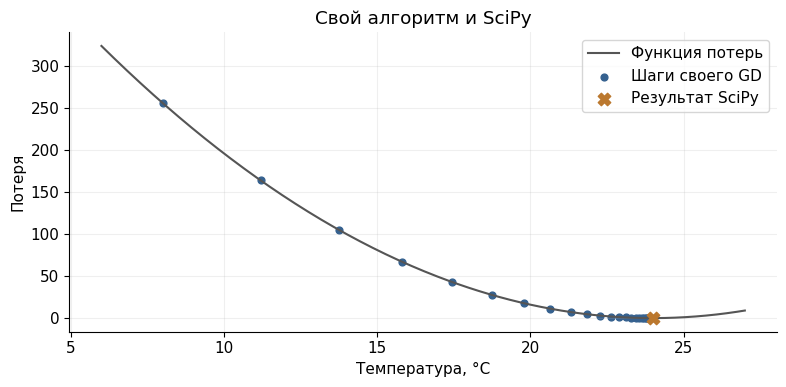

In [6]:
if scipy_result is not None and x_1 is not None:
    answer(2, [scipy_result.x[0], temperature_loss(scipy_result.x), abs(x_1[0] - scipy_result.x[0])])
    plot_comparison(temperature_loss, history_1, scipy_result.x)

## 3. Обогрев и освещение

$t$ и $l$ — нормированные уровни обогрева и освещения. $C$ — потеря комфорта растений: подбери настройки так, чтобы она была как можно меньше.

$$
\theta=(t,l),\qquad C(t,l)=(t-1)^2+2(l-1)^2,\qquad
\nabla C(t,l)=\begin{pmatrix}2(t-1)\\4(l-1)\end{pmatrix}.
$$

$$
\theta_0=(0,0),\qquad\alpha=0.1,\qquad N=30.
$$

Напиши функцию потерь и градиент. Запусти свой GD.

**Ответы в форме** — по одному числу с точкой и 6 знаками после неё:

- **3а.** $t_{30}$
- **3б.** $l_{30}$
- **3в.** $C(t_{30},l_{30})$

In [7]:
def c(teta):
  t = teta[0]
  l = teta[1]
  return (t-1)**2 + 2*(l -1)**2


def gradient_c(teta):
  t = teta[0]
  l = teta[1]
  return np.array([2*(t-1), 4*(l-1)])



teta30, history = gradient_descent(gradient_c, np.array([0,0]),  0.1, 30)
print(f"{teta30[0]:.6f} {teta30[1]:.6f} {c(teta30):.6f}")


0.998762 1.000000 0.000002


## 4. Чёрный ящик контроллера

В журнале сохранился расход энергии при разных настройках обогрева и света. Восстанови коэффициенты модели, чтобы её прогнозы были близки к измерениям.

`journal["settings"]` — $(t_i,l_i)$, `journal["energy"]` — измеренный расход $y_i$; $n$ — число записей. $a,b$ описывают расход на обогрев и свет, $c$ — постоянный расход, $p$ — вектор этих коэффициентов.

$$
p=(a,b,c),\qquad \widehat E(t,l)=at^2+bl^2+c,\qquad X_i=(t_i^2,l_i^2,1).
$$

$X_i$ — строка матрицы признаков $X$, $M$ — средняя ошибка модели:

$$
M(p)=\frac{1}{n}\sum_{i=1}^n((Xp)_i-y_i)^2,\qquad
\nabla M(p)=\frac{2}{n}X^\top(Xp-y).
$$

$$
p_0=(0,0,0),\qquad \alpha=0.1,\qquad N=5000.
$$

Собери $X$, напиши $M$ и градиент, восстанови $p$ своим GD. Сохрани коэффициенты без округления в `energy_parameters`.

**Ответы в форме** — по одному числу с точкой и 6 знаками после неё:

- **4а.** $a$
- **4б.** $b$
- **4в.** $c$
- **4г.** $\widehat E(0.5,0.5)$
- **4д.** $M(p)$

In [8]:
import numpy as np

data = np.load('greenhouse_data.npz')

t = data['settings'][:, 0]
l = data['settings'][:, 1]
y = data['energy']

X = np.column_stack((t**2, l**2, np.ones_like(t)))

def M(p):
  predictions = X @ p
  return np.mean((predictions - y)**2)

def grad_M(p):
  predictions = X @ p
  n = len(y)
  return (2.0 / n) * (X.T @ (predictions - y))

p0 = np.array([0.0, 0.0, 0.0])

energy_parameters, history4 = gradient_descent(grad_M, p0, 0.1, 5000)

a, b, c = energy_parameters
E_05_05 = (0.5**2)*a + (0.5**2)*b + c
loss_val = M(energy_parameters)

print(f"4а (a): {a:.6f}")
print(f"4б (b): {b:.6f}")
print(f"4в (c): {c:.6f}")
print(f"4г (E(0.5,0.5)): {E_05_05:.6f}")
print(f"4д (M(p)): {loss_val:.6f}")

4а (a): 0.797927
4б (b): 1.202424
4в (c): 0.152619
4г (E(0.5,0.5)): 0.652706
4д (M(p)): 0.000169


## 5. Экономия батареи

$\lambda$ — вес расхода энергии. Напиши функцию потерь и градиент, используя $C$ из задачи 3 и $\widehat E$ из задачи 4:

$$
J_\lambda(t,l)=C(t,l)+\lambda\widehat E(t,l),\qquad
\lambda_{\text{обычный}}=0.1,\quad\lambda_{\text{аварийный}}=1.
$$

$$
\theta_0=(0,0),\qquad N=200,\qquad
\alpha_\lambda=\frac{1}{2\max(1+\lambda a,\;2+\lambda b)}.
$$

Шаг $\alpha$ задаёт размер обновления параметров. При увеличении $\lambda$ растут коэффициенты при $t^2$ и $l^2$: функция становится круче, поэтому шаг уменьшаем. Внутри каждого режима шаг постоянный.

Запусти свой GD для обоих режимов. Выведи $T,I$ в °C и лк, $\widehat E$ — расход за интервал, $C$ — потерю комфорта.

Перевод нормированных настроек:

$$
T=10+15t,\qquad I=1000l.
$$

**Ответы в форме** — по одному числу с точкой и 6 знаками после неё:

- **5а.** $T_{\mathrm{обычный}}$ (°C)
- **5б.** $I_{\mathrm{обычный}}$ (лк)
- **5в.** $\widehat E_{\mathrm{обычный}}$
- **5г.** $C_{\mathrm{обычный}}$
- **5д.** $T_{\mathrm{аварийный}}$ (°C)
- **5е.** $I_{\mathrm{аварийный}}$ (лк)
- **5ж.** $\widehat E_{\mathrm{аварийный}}$
- **5з.** $C_{\mathrm{аварийный}}$

Пример убывающего шага по номеру итерации $k$ (с нуля). Для задания используй постоянный шаг каждого режима, заданный выше:

In [9]:
def decreasing_step_example(x, grad_f, k):
    learning_rate = 0.1 / (k + 1)
    return x - learning_rate * grad_f(x)

In [10]:
# TODO: функция потерь, градиент, два запуска GD и вывод ответа 5.
a1, b1, c1 = energy_parameters

def comfort_loss(teta):
  t = teta[0]
  l = teta[1]
  return (t-1)**2 + 2*(l -1)**2

def E(teta):
  t = teta[0]
  l = teta[1]
  return t**2 * a1 + l**2 *b1 + c1

def J(teta, lambd):
  return comfort_loss(teta) + lambd * E(teta)

def E_grad(teta):
  t, l = teta
  return np.array([2*a1*t, 2*l*b1])

def J_grad(teta, lambd):
  return gradient_c(teta) + lambd * E_grad(teta)

teta0 = np.array([0.0, 0.0])

lambda_norm = 0.1
alpha_norm = 1 / (2 * max(1 + lambda_norm * a1, 2 + lambda_norm * b1))

lambda_emerg = 1.0
alpha_emerg = 1 / (2 * max(1 + lambda_emerg * a1, 2 + lambda_emerg * b1))

TandI_norm, history5 = gradient_descent(
    lambda teta: J_grad(teta, lambda_norm),
    teta0,
    alpha_norm,
    200
)

TandI_emerg, history6 = gradient_descent(
    lambda teta: J_grad(teta, lambda_emerg),
    teta0,
    alpha_emerg,
    200
)

T_norm = 10 + 15 * TandI_norm[0]
I_norm = 1000 * TandI_norm[1]
E_norm_val = E(TandI_norm)
C_norm_val = comfort_loss(TandI_norm)

T_emerg = 10 + 15 * TandI_emerg[0]
I_emerg = 1000 * TandI_emerg[1]
E_emerg_val = E(TandI_emerg)
C_emerg_val = comfort_loss(TandI_emerg)

answer(5, [T_norm, I_norm, E_norm_val, C_norm_val, T_emerg, I_emerg, E_emerg_val, C_emerg_val])

5а: 23.891555
5б: 943.288371
5в: 1.906884
5г: 0.011893
5д: 18.342940
5е: 624.526922
5ж: 0.868447
5з: 0.478922


## 6. Прогноз роста

Датчик записывал прирост растений при разных настройках теплицы. Подбери модель, которая предсказывает прирост $g$ в мм/сутки по $t,l$.

Первая ячейка загружает данные в `growth`. В коде ниже `growth_settings` — NumPy-массив размера `(n, 2)`: столбцы содержат $t_i,l_i$; `measured_growth` — массив размера `(n,)` с измеренными приростами $g_i$ в том же порядке. Здесь $n$ — число записей. Неизвестные коэффициенты $\beta_t,\beta_l$ описывают влияние обогрева и света, $\beta_0$ — свободный член:

$$
\beta=(\beta_t,\beta_l,\beta_0),\qquad
\widehat g(t,l)=\beta_t t+\beta_l l+\beta_0.
$$

$R$ — средняя квадратичная ошибка прогноза:

$$
R(\beta)=\frac{1}{n}\sum_{i=1}^n\left(\widehat g(t_i,l_i)-g_i\right)^2.
$$

$$
\beta_{\mathrm{start}}=(0,0,0),\quad \alpha=0.1,\quad N=5000.
$$

Напиши прогноз, ошибку и её градиент. Найди коэффициенты своим GD и предскажи прирост при T = 22 °C и I = 800 лк. Перевод нормированных настроек:

$$
T=10+15t,\qquad I=1000l.
$$

**Ответы в форме** — по одному числу с точкой и 6 знаками после неё:

- **6а.** $\beta_t$
- **6б.** $\beta_l$
- **6в.** $\beta_0$
- **6г.** $\widehat g$ (мм/сутки)
- **6д.** $R(\beta)$

In [11]:
growth_settings = growth["settings"]
measured_growth = growth["rate"]

X = np.column_stack((growth_settings[:, 0], growth_settings[:, 1], np.ones_like(growth_settings[:, 0])))

def R(beta):
  return np.mean((X @ beta - measured_growth)**2)

def R_gradient(beta):
  n = len(measured_growth)
  return (2.0 / n) * (X.T @ (X @ beta - measured_growth))

beta0 = np.array([0.0, 0.0, 0.0])

parametrs, history6 = gradient_descent(R_gradient, beta0, 0.1, 5000)

beta_t = parametrs[0]
beta_l = parametrs[1]
beta_0 = parametrs[2]

t_target = (22.0 - 10.0) / 15.0
l_target = 800.0 / 1000.0


g_pred = beta_t * t_target + beta_l * l_target + beta_0
loss_val = R(parametrs)


answer(6, [beta_t, beta_l, beta_0, g_pred, loss_val])

6а: 1.405731
6б: 2.079426
6в: 0.312997
6г: 3.101122
6д: 0.000659


In [12]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


**Молодцы! Вы обучили линейную регрессию своим GD:** подобрали коэффициенты линейного прогноза, минимизируя среднюю квадратичную ошибку.